<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [XGBoost](https://github.com/Query-farm/vgi-xgboost)

Train, tune, score and explain gradient-boosted tree models on your tables with plain SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-xgboost/blob/main/notebooks/03_selection_scores_and_new_rows.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-xgboost/blob/main/notebooks/README.md)

## A selection score is not the final evaluation

How do out-of-fold errors, a hyperparameter leaderboard and a separate holdout answer different questions? We generate 240 synthetic regression rows through the worker, reserve 48 before tuning, and restrict every selection operation to the other 192.

The example compares a fixed depth-2 model's out-of-fold predictions with its fold scores, then searches three depths and scores the selected model once on the reserved rows. All targets are synthetic numerical units, with no real-world outcome interpretation. This is a small reproducible comparison, not evidence that a chosen depth generalizes to another dataset.

### Change the cross-validation partition

`CV_FOLDS` is 3 or 6; both divide 192 evenly. Within the development relation, rows are ordered by `sample_id`. The released worker uses scikit-learn's integer-fold regression convention: contiguous, unshuffled KFold splits in that order. The input generator has already produced an independently shuffled synthetic row order; this is not a time-series validation method. The experiment changes folds while leaving source rows, 48-row holdout and three-candidate grid fixed.

In [1]:
CV_FOLDS = 3

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.38":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.38"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
import os
from tempfile import TemporaryDirectory

check_runtime()
prepare("xgboost")
import xgboost_example as example

example.validate_folds(CV_FOLDS)
model_directory = TemporaryDirectory(prefix="xgboost-example-")
previous_env = {k: os.environ.get(k) for k in ("XGBOOST_MODELS_DIR", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS")}
os.environ.update(XGBOOST_MODELS_DIR=model_directory.name, OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1")
session = connect(globals())
theme()

### Use the public release in an isolated registry

The visible release tag is checked against an immutable source revision by the companion. Its own frozen dependency lock supplies the runtime. Git/uv and an XGBoost OpenMP runtime are needed; macOS commonly uses Homebrew `libomp`. The model registry and SQL-secret directory are disposable, and no shared service is contacted for model storage.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'xgboost' (TYPE vgi, LOCATION 'uv run --no-project --python 3.13 python xgboost_release.py v0.1.0');

,Success


### Materialize the generator once, then declare roles

The release wraps scikit-learn's `make_regression`: three numerical features, two informative features, Gaussian target noise with standard deviation 12, and random seed 7. An ID labels each returned row; it is never a feature. The other input need not have positive importance. The fingerprint below checks that a fold experiment uses the same generated population.

In [5]:
%%sql
CREATE TABLE generated AS SELECT * FROM xgboost.main.make_regression(
 n_samples:=240,n_features:=3,n_informative:=2,noise:=12.0,random_state:=7);
CREATE TABLE samples AS SELECT *,CASE WHEN sample_id%5=0 THEN 'Reserved' ELSE 'Development' END AS role FROM generated;
SELECT role,count(*) AS rows,min(sample_id) AS first_id,max(sample_id) AS last_id FROM samples GROUP BY role ORDER BY role;

,role,rows,first_id,last_id
0,Development,192,1,239
1,Reserved,48,0,235


In [6]:
%%sql fingerprint <<
SELECT md5(string_agg(concat_ws('|',sample_id::VARCHAR,feature_0::VARCHAR,feature_1::VARCHAR,feature_2::VARCHAR,target::VARCHAR),'
' ORDER BY sample_id)) AS source_sha FROM generated;

In [7]:
display(fingerprint)

,source_sha
0,e17dc9a526285c4ecb00e481ec10f650


### Reconcile row-level out-of-fold errors with fold scores

Both calls use the same fixed depth-2 regressor, 40 rounds, learning rate 0.1, seed 0, ordered development input and fold count. `cross_val_predict` gives one prediction for each development row from a model that excluded its fold. `cross_val_score` gives **negative RMSE** per fold. We negate it for display, then reconcile pooled RMSE with the root mean of squared fold RMSEs. Equal fold populations make that identity valid here; the plain arithmetic mean of fold RMSEs is a different quantity.

No model is persisted by either cross-validation call. These scores describe a fixed candidate before the separate grid search.

In [8]:
%%sql
CREATE TABLE out_of_fold AS SELECT * FROM xgboost.main.cross_val_predict(
 (SELECT sample_id,feature_0,feature_1,feature_2,target FROM samples WHERE role='Development' ORDER BY sample_id),
 estimator:='xgb_regressor',target:='target',id:='sample_id',cv:={{ CV_FOLDS }},
 params:='{"n_estimators":40,"max_depth":2,"learning_rate":0.1,"random_state":0}');
CREATE TABLE fold_scores AS SELECT * FROM xgboost.main.cross_val_score(
 (SELECT sample_id,feature_0,feature_1,feature_2,target FROM samples WHERE role='Development' ORDER BY sample_id),
 estimator:='xgb_regressor',target:='target',id:='sample_id',cv:={{ CV_FOLDS }},scoring:='neg_root_mean_squared_error',
 params:='{"n_estimators":40,"max_depth":2,"learning_rate":0.1,"random_state":0}');
CREATE TABLE oof_errors AS SELECT s.sample_id,p.prediction,s.target,p.prediction-s.target AS error
 FROM samples s JOIN out_of_fold p USING(sample_id);
CREATE TABLE reconciliation AS SELECT
 (SELECT sqrt(avg(error*error)) FROM oof_errors) AS pooled_rmse,
 sqrt(avg(score*score)) AS pooled_from_equal_folds_rmse,
 -avg(score) AS mean_fold_rmse FROM fold_scores;

,Count


In [9]:
%%sql folds <<
SELECT fold+1 AS fold,-score AS rmse,192/{{ CV_FOLDS }} AS evaluation_rows FROM fold_scores ORDER BY fold;

In [10]:
%%sql reconciled <<
SELECT * FROM reconciliation;

In [11]:
display(folds)
display(reconciled)
prose(f"**Pooled out-of-fold RMSE is {reconciled.pooled_rmse.iloc[0]:.3f} target units.** Reconstructing it from the equal-sized fold scores gives {reconciled.pooled_from_equal_folds_rmse.iloc[0]:.3f}; their plain mean is {reconciled.mean_fold_rmse.iloc[0]:.3f}. Fold variation is descriptive, not a confidence interval.")

,fold,rmse,evaluation_rows
0,1,24.831013,64.0
1,2,17.750983,64.0
2,3,21.083310,64.0


,pooled_rmse,pooled_from_equal_folds_rmse,mean_fold_rmse
0,21.417925,21.417925,21.221769


**Pooled out-of-fold RMSE is 21.418 target units.** Reconstructing it from the equal-sized fold scores gives 21.418; their plain mean is 21.222. Fold variation is descriptive, not a confidence interval.

### Select on development rows and refit once

The grid searches depths 1, 3 and 6 with 40 rounds and the same learning rate/seed. The worker ranks the **mean fold score**, so the largest negative RMSE (smallest positive RMSE) wins. Exactly one row contains the refitted model BLOB; `model_name` stores that same selected model after fitting all 192 development rows. We display parameters and scores, not binary model bytes. A tie could have several rank-1 rows; the single BLOB identifies the one actually selected.

Choosing the best score after comparing candidates uses the development population for selection. That winning score is not an untouched estimate of final performance. Also, this release's search registry field named `train_score` stores the best cross-validation score, unlike direct fit's in-sample R²; this notebook uses the explicit leaderboard columns instead.

In [12]:
%%sql
CREATE TABLE search_results AS SELECT * FROM xgboost.main.grid_search(
 (SELECT sample_id,feature_0,feature_1,feature_2,target FROM samples WHERE role='Development' ORDER BY sample_id),
 target:='target',id:='sample_id',cv:={{ CV_FOLDS }},scoring:='neg_root_mean_squared_error',model_name:='cv_selected',
 estimator:=union_value(xgb_regressor:={'n_estimators':[40],'max_depth':[1,3,6],'learning_rate':[0.1],'random_state':[0]}));
CREATE TABLE leaderboard AS SELECT (params::JSON->>'max_depth')::INTEGER AS depth,rank,
 -mean_test_score AS mean_cv_rmse,std_test_score AS fold_sd,model IS NOT NULL AS selected FROM search_results;

,Count


In [13]:
%%sql grid <<
SELECT * FROM leaderboard ORDER BY depth;

### Open the reserved set after selection

Only the selected model sees the reserved predictors. The target joins back after prediction; the reference predictor is the development-set mean target. We retain a poor score if that is what the release returns. Comparing a fold experiment after seeing this holdout is an educational sensitivity exercise; repeated tuning would spend its untouched-test role.

In [14]:
%%sql
CREATE TABLE held_out_predictions AS SELECT * FROM xgboost.main.predict(
 (SELECT sample_id,feature_0,feature_1,feature_2 FROM samples WHERE role='Reserved' ORDER BY sample_id),
 model_name:='cv_selected',id:='sample_id');
CREATE TABLE holdout_evaluation AS
SELECT count(*) AS reserved_rows,sqrt(avg(pow(p.prediction-s.target,2))) AS selected_rmse,
 sqrt(avg(pow((SELECT avg(target) FROM samples WHERE role='Development')-s.target,2))) AS mean_baseline_rmse
FROM held_out_predictions p JOIN samples s USING(sample_id);

,Count


In [15]:
%%sql holdout <<
SELECT * FROM holdout_evaluation;

,depth,rank,mean_cv_rmse,fold_sd,selected
0,1,3,29.081472,4.016415,False
1,3,1,19.321077,2.363308,True
2,6,2,20.306630,2.184143,False


,reserved_rows,selected_rmse,mean_baseline_rmse
0,48,21.722432,101.229614


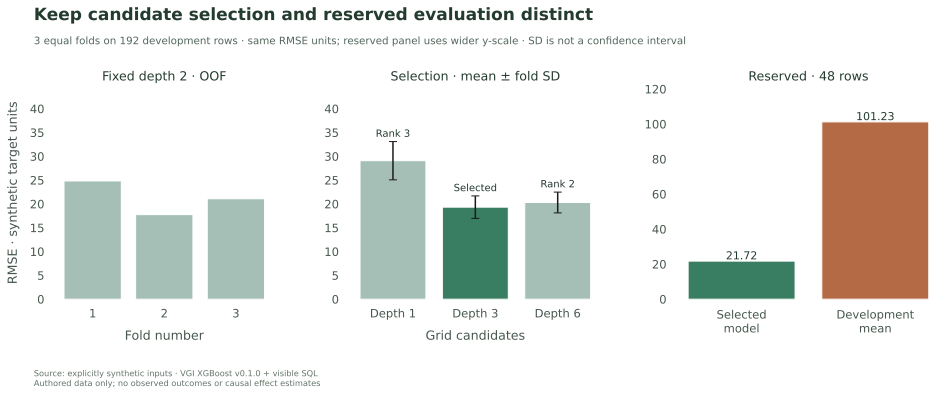

**Depth 3 was selected using mean fold RMSE 19.32.** Its separately measured reserved-set RMSE is 21.72, versus 101.23 for the development-mean baseline. These are target units on different evaluation populations, not interchangeable scores.

In [16]:
display(grid)
display(holdout)
example.selection_scores(folds, grid, holdout, CV_FOLDS)
chosen = grid[grid.selected].iloc[0]
prose(f"**Depth {int(chosen.depth)} was selected using mean fold RMSE {chosen.mean_cv_rmse:.2f}.** Its separately measured reserved-set RMSE is {holdout.selected_rmse.iloc[0]:.2f}, versus {holdout.mean_baseline_rmse.iloc[0]:.2f} for the development-mean baseline. These are target units on different evaluation populations, not interchangeable scores.")

### Check separation, score arithmetic and model selection

We check complete row accounting, no reserved ID in the out-of-fold results, equal fold populations, numerical score reconciliation and one selected model. These invariants guard evaluation mechanics without asserting a preferred model or a minimum accuracy.

In [17]:
%%sql checks <<
SELECT '240 unique generated rows' AS check_name,count(*)=240 AND count(DISTINCT sample_id)=240 AS passed FROM generated
UNION ALL SELECT '192 development and 48 reserved',count(*) FILTER(WHERE role='Development')=192 AND count(*) FILTER(WHERE role='Reserved')=48 FROM samples
UNION ALL SELECT '192 unique out-of-fold IDs',count(*)=192 AND count(DISTINCT sample_id)=192 FROM out_of_fold
UNION ALL SELECT 'No reserved OOF IDs',count(*)=0 FROM out_of_fold p JOIN samples s USING(sample_id) WHERE s.role='Reserved'
UNION ALL SELECT 'Requested fold count',count(*)={{ CV_FOLDS }} AND count(DISTINCT fold)={{ CV_FOLDS }} FROM fold_scores
UNION ALL SELECT 'Finite negative RMSE scores',bool_and(isfinite(score) AND score<=0) FROM fold_scores
UNION ALL SELECT 'Pooled RMSE reconciles',abs(pooled_rmse-pooled_from_equal_folds_rmse)<1e-7 FROM reconciliation
UNION ALL SELECT 'Three candidate depths',count(*)=3 AND count(DISTINCT depth)=3 FROM leaderboard
UNION ALL SELECT 'One actual selected model',count(*)=1 AND min(rank)=1 FROM leaderboard WHERE selected
UNION ALL SELECT 'Selected score is minimum',abs((SELECT mean_cv_rmse FROM leaderboard WHERE selected)-min(mean_cv_rmse))<1e-9 FROM leaderboard
UNION ALL SELECT '48 unique held-out predictions',count(*)=48 AND count(DISTINCT sample_id)=48 FROM held_out_predictions
UNION ALL SELECT 'Selected fit has 192 rows and three features',n_samples=192 AND n_features=3 FROM xgboost.main.model_info('cv_selected')
UNION ALL SELECT 'Finite holdout scores',reserved_rows=48 AND isfinite(selected_rmse) AND isfinite(mean_baseline_rmse) FROM holdout_evaluation;

In [18]:
display(checks)
assert len(checks) == 13 and checks.passed.fillna(False).all()
prose(f"**All {len(checks)} separation and arithmetic checks passed.** Selection and final evaluation retain distinct populations even when their numerical scores happen to be close.")

,check_name,passed
0,240 unique generated rows,True
1,192 development and 48 reserved,True
2,192 unique out-of-fold IDs,True
3,No reserved OOF IDs,True
4,Requested fold count,True
5,Finite negative RMSE scores,True
6,Pooled RMSE reconciles,True
7,Three candidate depths,True
8,One actual selected model,True
9,Selected score is minimum,True


**All 13 separation and arithmetic checks passed.** Selection and final evaluation retain distinct populations even when their numerical scores happen to be close.

### Change folds, not the rows

Set **`CV_FOLDS = 6`**, restart and run all. The source fingerprint, 192/48 partition, candidate depths and hyperparameters stay fixed. Compare fold-score variation, selected depth and reserved-set error. A change in which candidate wins is sensitivity to this partition, not proof that one fold count is universally better.

In [19]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
model_directory.cleanup()
for key, value in previous_env.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-xgboost](https://github.com/Query-farm/vgi-xgboost)